# TDX audit: reproducible aggregate review

NO LIVE MONEY. This notebook reviews the real audit aggregates committed with this PR. It contains no raw prices, supplier responses, or private security inventory. Software success does not certify PIT or HFQ. The full checks are inspectable in `examples/research/audit_tdx_quality.py` and the separate review implementation. Missing private inputs must remain UNKNOWN.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/research/evidence/tdx-data-quality-v1/summary.json").exists())
evidence = root / "docs/research/evidence/tdx-data-quality-v1"
summary = json.loads((evidence / "summary.json").read_bytes())
assert summary["financial_admission"] is False
assert summary["hfq_status"] == "HFQ_UNVERIFIED"
assert summary["frozen_symbols_unchanged"] is True
print({key: summary[key] for key in ["baseline_commit", "integrity_errors", "private_files_changed", "hfq_status"]})
print(summary["counts"])

{'baseline_commit': '3d7d2a20e5ee2f5a4be55cf55f912ef14448e52b', 'integrity_errors': 0, 'private_files_changed': 0, 'hfq_status': 'HFQ_UNVERIFIED'}
{'audit_FAIL': 3, 'audit_PASS': 4510, 'audit_WARN': 4861, 'files': 9374, 'full_history_A_SHARE_CANDIDATE': 2968, 'full_history_B_SHARE_CANDIDATE': 54, 'full_history_CONVERTIBLE_BOND_CANDIDATE': 18, 'full_history_FUND_CANDIDATE': 411, 'full_history_INDEX_CANDIDATE': 103, 'full_history_UNKNOWN': 966, 'full_history_files': 4520, 'market_bj': 350, 'market_sh': 4721, 'market_sz': 4303, 'missing_grid_A_SHARE_CANDIDATE': 732529, 'missing_grid_B_SHARE_CANDIDATE': 243, 'missing_grid_CONVERTIBLE_BOND_CANDIDATE': 193838, 'missing_grid_FUND_CANDIDATE': 1015333, 'missing_grid_INDEX_CANDIDATE': 613, 'missing_grid_UNKNOWN': 252723, 'observed_grid_A_SHARE_CANDIDATE': 6739523, 'observed_grid_B_SHARE_CANDIDATE': 104355, 'observed_grid_CONVERTIBLE_BOND_CANDIDATE': 227236, 'observed_grid_FUND_CANDIDATE': 1523180, 'observed_grid_INDEX_CANDIDATE': 138851, 'observ

## Reconcile coverage denominators

The denominator is the local candidate-file count times actual observed native benchmark sessions in each month. It is not a historical CSI500 membership denominator or a verified listing-period denominator.

In [2]:
coverage = pd.read_csv(evidence / "coverage-monthly.csv")
assert (coverage.observed_grid <= coverage.expected_grid).all()
grouped = coverage.groupby("security_type_candidate")[["observed_grid", "expected_grid"]].sum()
for kind, row in grouped.iterrows():
    assert row.observed_grid == summary["counts"]["observed_grid_" + kind]
    assert row.expected_grid - row.observed_grid == summary["counts"]["missing_grid_" + kind]
grouped["observed_fraction"] = grouped.observed_grid / grouped.expected_grid
display(grouped)

,observed_grid,expected_grid,observed_fraction
security_type_candidate,,,
A_SHARE_CANDIDATE,6739523,7472052,0.901964
B_SHARE_CANDIDATE,104355,104598,0.997677
CONVERTIBLE_BOND_CANDIDATE,227236,421074,0.539658
FUND_CANDIDATE,1523180,2538513,0.600028
INDEX_CANDIDATE,138851,139464,0.995605
UNKNOWN,1642110,1894833,0.866625


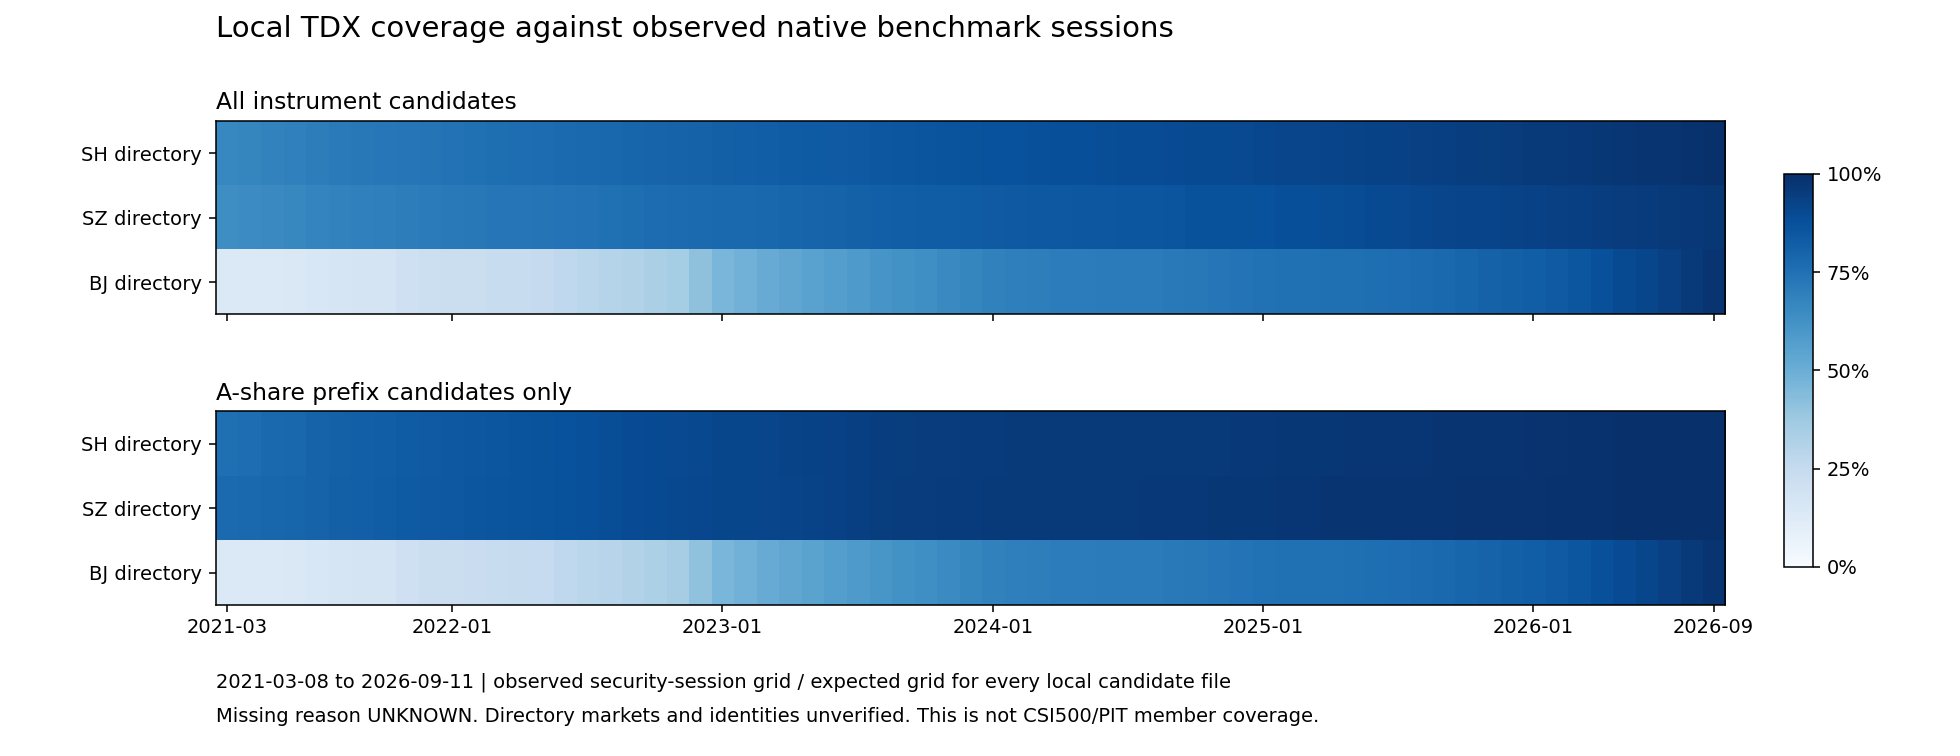

In [3]:
display(Image(filename=str(evidence / "coverage.png"), width=980))

## Frozen sample: numbers and qualification remain separate

Fixed existing candidate scale 100, Decimal equality, zero tolerance, no fitted ratios. All ten names are retained, including absent TDX exit samples. A candidate numerical match does not authenticate source units or adjustment settings.

In [4]:
comparison = pd.read_csv(evidence / "frozen-comparison.csv")
assert comparison.symbol.nunique() == 10
assert not comparison.financially_verified.any()
assert (comparison.EXACT_MATCH + comparison.DIFFERENT + comparison.NOT_COMPARED == comparison.expected_sessions).all()
display(comparison.query("reference == 'EASTMONEY' and basis == 'RAW'")[["symbol", "tdx_sessions", "reference_sessions", "EXACT_MATCH", "DIFFERENT", "SOURCE_UNIT_UNVERIFIED", "NO_VALID_REFERENCE"]])

,symbol,tdx_sessions,reference_sessions,EXACT_MATCH,DIFFERENT,SOURCE_UNIT_UNVERIFIED,NO_VALID_REFERENCE
0,600000.SH,1341,1341,1341,0,1341,0
4,000001.SZ,1341,1341,1341,0,1341,0
8,600519.SH,1341,1341,1341,0,1341,0
12,000002.SZ,1341,1341,1341,0,1341,0
16,300750.SZ,1341,1341,1341,0,1341,0
20,688981.SH,1335,1335,1335,0,1335,6
24,601059.SH,860,860,860,0,860,481
28,001289.SZ,1124,1124,1124,0,1124,217
32,600112.SH,0,786,0,0,0,1341
36,000961.SZ,0,767,0,0,0,1341


## Existing 50-name experiment and GBBQ

The existing 50 names are reused without reselection. GBBQ is a candidate event source. Event-chain completeness, historical float-share definitions, corrections and an independently supported HFQ anchor remain unverified.

In [5]:
fifty = json.loads((evidence / "existing-50-summary.json").read_bytes())
gbbq = json.loads((evidence / "gbbq-summary.json").read_bytes())
assert fifty["financial_admission"] is False
assert gbbq["anchor"] is None and gbbq["computed_hfq"] is None and gbbq["certified_hfq_sessions"] == 0
print(fifty)
print({"gbbq_records": gbbq["records"], "candidate_categories": gbbq["category_bytes"], "pilot": gbbq["pilot"]})

{'complete_five_year_hfq_four_prices': 'UNVERIFIED', 'existing_end': '2026-09-11', 'existing_rows': 20586, 'existing_start': '2025-01-02', 'financial_admission': False, 'historical_identity_and_status': 'UNVERIFIED', 'historical_turnover': 'UNVERIFIED', 'missing_reason': 'UNKNOWN', 'names': 50, 'pit': False, 'schema': 'EXISTING_FROZEN_50_TDX_COVERAGE_V1', 'selection': 'unchanged existing 50-name experiment; no reselection', 'source_sha256': '6e6b34bfe6d9e85ef5a5ffe5694cce7fd0a9f03a0f1ed10247877d22f51df1a9', 'tdx_absent': 0, 'tdx_expected_history_grid': 67050, 'tdx_full_history_files': 42, 'tdx_observed_history_grid': 66968, 'tdx_present': 50}
{'gbbq_records': 200878, 'candidate_categories': {'1': 65872, '10': 274, '11': 408, '12': 8, '13': 9, '14': 15, '15': 91, '2': 4298, '3': 5447, '4': 2, '5': 115412, '6': 69, '7': 19, '8': 1118, '9': 7836}, 'pilot': {'candidate_cash_minus_official_exact': '-9.5367431640625E-9', 'candidate_events': 20, 'float32_rounding_contract': 'UNVERIFIED', 'hfq

## Optional real-asset replay

Default execution reads only published aggregates. To repeat the full audit, set the five environment variables below to existing authorized local assets and a NEW ignored output directory, then explicitly enable the cell. No download occurs. Public checkout alone cannot replace missing real assets with synthetic data.

In [6]:
RUN_PRIVATE_AUDIT = False
if RUN_PRIVATE_AUDIT:
    import os, subprocess
    command = [os.environ["TDX_AUDIT_PYTHON"], "-B", "-m", "examples.research.audit_tdx_quality",
               "--private-root", os.environ["TDX_PRIVATE_CHECKOUT"],
               "--output", os.environ["TDX_AUDIT_NEW_OUTPUT"],
               "--pilot-manifest", os.environ["TDX_PILOT_MANIFEST"],
               "--decoder-reference", os.environ["TDX_DECODER_REFERENCE"]]
    subprocess.run(command, cwd=root, check=True)
else:
    print("Real-asset replay not requested; aggregate review only. HFQ_UNVERIFIED.")

Real-asset replay not requested; aggregate review only. HFQ_UNVERIFIED.
